<a href="https://colab.research.google.com/github/dinhphu-coder/PHUWEB/blob/main/BaiTap1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🍜 AI phân loại & chấm điểm món ăn Việt Nam (bản Google Colab)

Mô hình **multi-task** dùng chung một backbone EfficientNet-B0 với 2 đầu ra:
1. **Phân loại** món ăn (phở, bún bò Huế, bánh mì, ...)
2. **Chấm điểm** 0–10 (trình bày / chất lượng) từ ảnh — *chỉ hoạt động khi có cột điểm trong dữ liệu*

Ngoài ra có **điểm sức khỏe** tính theo quy tắc từ bảng dinh dưỡng.

### Dữ liệu tích hợp sẵn
Notebook tự tải bộ **30VNFoods** (Kaggle: `quandang/vietnamese-foods`, 30 món Việt, hàng chục nghìn ảnh) — chỉ cần chạy ô "Nạp dữ liệu". Cũng có thể dùng dữ liệu riêng bằng cách upload `data.zip` hoặc lấy từ Google Drive.

### Cách dùng trên Colab
1. Bật GPU: **Runtime → Change runtime type → T4 GPU**.
2. Chạy lần lượt từng ô từ trên xuống.
3. Nếu ô tải Kaggle yêu cầu, upload file `kaggle.json` (Kaggle → Settings → *Create New Token*).

> 30VNFoods không có điểm chấm, nên nhánh chấm điểm sẽ tự tắt và chỉ huấn luyện phân loại. Muốn chấm điểm, hãy thêm cột `score` vào `labels.csv` của bạn.

## 1. Kiểm tra môi trường

In [1]:
import torch
print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "KHÔNG CÓ (hãy bật GPU trong Runtime > Change runtime type)")

PyTorch: 2.11.0+cu130
GPU: Tesla T4


## 2. Import & cấu hình

In [2]:
import os, json, random, shutil, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# ---- Cấu hình ----
EPOCHS     = 15
BATCH_SIZE = 32
LR         = 3e-4
SCORE_LOSS_WEIGHT = 2.0             # trọng số nhánh chấm điểm
CKPT       = "/content/vn_food_model.pt"
SEED       = 42
DEVICE     = "cuda" if torch.cuda.is_available() else "cpu"

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("Thiết bị:", DEVICE)

Thiết bị: cuda


## 3. Nạp dữ liệu (chọn 1 trong 3 cách)
- `DATA_SOURCE = "kaggle"` *(mặc định)*: tự tải bộ **30VNFoods** từ Kaggle.
- `DATA_SOURCE = "upload"`: upload file `data.zip` của bạn từ máy.
- `DATA_SOURCE = "drive"`: lấy từ Google Drive — sửa `DRIVE_PATH` thành đường dẫn **thư mục hoặc file .zip**.

In [3]:
DATA_SOURCE = "kaggle"                      # "kaggle" | "upload" | "drive"
KAGGLE_SLUG = "quandang/vietnamese-foods"   # bộ 30VNFoods
DRIVE_PATH  = "/content/drive/MyDrive/data.zip"   # chỉ dùng khi DATA_SOURCE = "drive"

import subprocess, sys

def pip_install(pkg):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

def unzip_to(path, out="/content/data_unzipped"):
    shutil.rmtree(out, ignore_errors=True)
    with zipfile.ZipFile(path) as z:
        z.extractall(out)
    return out

if DATA_SOURCE == "kaggle":
    try:
        import kagglehub
    except ImportError:
        pip_install("kagglehub"); import kagglehub
    try:
        print("Đang tải", KAGGLE_SLUG, "(có thể mất vài phút)...")
        RAW_DIR = kagglehub.dataset_download(KAGGLE_SLUG)
    except Exception as e:
        print("Tải trực tiếp không được:", repr(e)[:200])
        print("-> Chuyển sang dùng kaggle.json. Hãy upload file kaggle.json:")
        from google.colab import files
        files.upload()
        kdir = os.path.expanduser("~/.kaggle")
        os.makedirs(kdir, exist_ok=True)
        shutil.move("kaggle.json", os.path.join(kdir, "kaggle.json"))
        os.chmod(os.path.join(kdir, "kaggle.json"), 0o600)
        pip_install("kaggle")
        RAW_DIR = "/content/kaggle_data"
        subprocess.check_call(["kaggle", "datasets", "download", "-d", KAGGLE_SLUG, "-p", RAW_DIR, "--unzip"])

elif DATA_SOURCE == "upload":
    from google.colab import files
    print("Chọn file data.zip để upload...")
    up = files.upload()
    zips = [k for k in up if k.lower().endswith(".zip")]
    assert zips, "Không thấy file .zip nào. Hãy nén dữ liệu thành data.zip rồi upload lại."
    RAW_DIR = unzip_to(zips[0])

elif DATA_SOURCE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    assert os.path.exists(DRIVE_PATH), f"Không tìm thấy: {DRIVE_PATH}"
    RAW_DIR = unzip_to(DRIVE_PATH) if DRIVE_PATH.lower().endswith(".zip") else DRIVE_PATH

else:
    raise ValueError('DATA_SOURCE phải là "kaggle", "upload" hoặc "drive"')

print("\nDữ liệu ở:", RAW_DIR)
for i, (d, dirs, fs) in enumerate(os.walk(RAW_DIR)):
    print(" ", d, f"({len(fs)} file)")
    if i >= 15:
        print("  ..."); break

Đang tải quandang/vietnamese-foods (có thể mất vài phút)...


100%|██████████| 4.17G/4.17G [04:01<00:00, 18.6MB/s]

Extracting files...



Dữ liệu ở: /root/.cache/kagglehub/datasets/quandang/vietnamese-foods/versions/11
  /root/.cache/kagglehub/datasets/quandang/vietnamese-foods/versions/11 (1 file)
  /root/.cache/kagglehub/datasets/quandang/vietnamese-foods/versions/11/Images (0 file)
  /root/.cache/kagglehub/datasets/quandang/vietnamese-foods/versions/11/Images/Validate (0 file)
  /root/.cache/kagglehub/datasets/quandang/vietnamese-foods/versions/11/Images/Validate/Bun thit nuong (75 file)
  /root/.cache/kagglehub/datasets/quandang/vietnamese-foods/versions/11/Images/Validate/Banh canh (97 file)
  /root/.cache/kagglehub/datasets/quandang/vietnamese-foods/versions/11/Images/Validate/Bun dau mam tom (92 file)
  /root/.cache/kagglehub/datasets/quandang/vietnamese-foods/versions/11/Images/Validate/Banh tet (68 file)
  /root/.cache/kagglehub/datasets/quandang/vietnamese-foods/versions/11/Images/Validate/Nem chua (54 file)
  /root/.cache/kagglehub/datasets/quandang/vietnamese-foods/versions/11/Images/Validate/Banh chung (50 

## 4. Đọc nhãn, làm sạch & chia train/val
Ô này tự nhận dạng cấu trúc dữ liệu (có `labels.csv` hoặc thư mục theo món).

Không có labels.csv -> dùng tên thư mục làm tên món (nhận diện cả thư mục Train/Validate/Test)
⚠ Không có đủ điểm trong dữ liệu -> TẮT nhánh chấm điểm, chỉ huấn luyện phân loại.

25136 ảnh, 30 món: ['banh_beo', 'banh_bot_loc', 'banh_can', 'banh_canh', 'banh_chung', 'banh_cuon', 'banh_duc', 'banh_gio', 'banh_khot', 'banh_mi', 'banh_pia', 'banh_tet', 'banh_trang_nuong', 'banh_xeo', 'bun_bo_hue', 'bun_dau_mam_tom', 'bun_mam', 'bun_rieu', 'bun_thit_nuong', 'ca_kho_to', 'canh_chua', 'cao_lau', 'chao_long', 'com_tam', 'goi_cuon', 'hu_tieu', 'mi_quang', 'nem_chua', 'pho', 'xoi_xeo']
Dùng cách chia sẵn của bộ dữ liệu: train=17581, val=2515


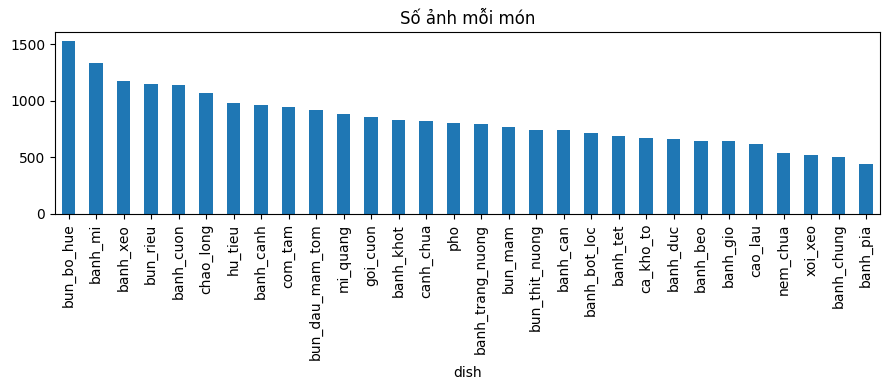

In [4]:
import unicodedata, re
IMG_EXT = (".jpg", ".jpeg", ".png", ".webp", ".bmp")
SPLIT_NAMES = {"train": "train", "training": "train", "val": "val", "valid": "val", "validate": "val",
               "validation": "val", "test": "test", "testing": "test"}

def norm(s):
    """'Bánh mì' -> 'banh_mi' (bỏ dấu, chữ thường, snake_case)."""
    s = unicodedata.normalize("NFD", str(s)).replace("đ", "d").replace("Đ", "D")
    s = "".join(c for c in s if unicodedata.category(c) != "Mn")
    return re.sub(r"[^a-z0-9]+", "_", s.lower()).strip("_")

# --- Tìm labels.csv (nếu có) ---
csv_dir = None
for d, _, fs in os.walk(RAW_DIR):
    if "labels.csv" in fs:
        csv_dir = d; break

if csv_dir:
    print("Phát hiện labels.csv ->", csv_dir)
    df = pd.read_csv(os.path.join(csv_dir, "labels.csv"))
    assert {"filename", "dish"} <= set(df.columns), "labels.csv cần có cột: filename, dish (và score nếu có)"
    IMG_ROOT = os.path.join(csv_dir, "images") if os.path.isdir(os.path.join(csv_dir, "images")) else csv_dir
    if "score" not in df.columns:
        df["score"] = np.nan
    if "split" not in df.columns:
        df["split"] = None
else:
    print("Không có labels.csv -> dùng tên thư mục làm tên món (nhận diện cả thư mục Train/Validate/Test)")
    rows = []
    for d, _, fs in os.walk(RAW_DIR):
        for f in fs:
            if f.lower().endswith(IMG_EXT):
                rel = os.path.relpath(os.path.join(d, f), RAW_DIR)
                parts = [norm(p) for p in rel.split(os.sep)[:-1]]
                split = next((SPLIT_NAMES[p] for p in parts if p in SPLIT_NAMES), None)
                rows.append({"filename": rel, "dish": os.path.basename(d), "score": np.nan, "split": split})
    df = pd.DataFrame(rows)
    IMG_ROOT = RAW_DIR
    assert len(df) > 0, "Không tìm thấy ảnh nào trong dữ liệu."

# --- Chuẩn hóa tên món ---
df["dish"] = df["dish"].apply(norm)
bad = set(df.dish) & set(SPLIT_NAMES)
assert not bad, (f"Ảnh nằm trực tiếp trong thư mục {bad} mà không chia theo món. "
                 "Hãy gửi kết quả ô trước (cây thư mục) để chỉnh cách đọc dữ liệu.")

# --- Làm sạch ---
exists = df.filename.apply(lambda f: os.path.exists(os.path.join(IMG_ROOT, f)))
assert exists.any(), f"Không khớp được ảnh nào với IMG_ROOT={IMG_ROOT}. Kiểm tra lại cột filename."
if (~exists).any():
    print(f"Cảnh báo: bỏ {(~exists).sum()} dòng không tìm thấy ảnh")
df = df[exists].reset_index(drop=True)

counts = df.dish.value_counts()
few = counts[counts < 2].index
if len(few):
    print("Bỏ các món chỉ có 1 ảnh:", list(few))
    df = df[~df.dish.isin(few)].reset_index(drop=True)

# --- Điểm: có thật hay không? ---
HAS_SCORE = df.score.notna().all()
if not HAS_SCORE:
    print("⚠ Không có đủ điểm trong dữ liệu -> TẮT nhánh chấm điểm, chỉ huấn luyện phân loại.")
    SCORE_LOSS_WEIGHT = 0.0
    df["score"] = 0.0

classes = sorted(df.dish.unique())
c2i = {c: i for i, c in enumerate(classes)}
print(f"\n{len(df)} ảnh, {len(classes)} món:", classes)

# --- Chia train/val: ưu tiên chia sẵn của bộ dữ liệu, nếu không thì chia ngẫu nhiên ---
splits = set(df["split"].dropna())
if "train" in splits and (splits & {"val", "test"}):
    val_name = "val" if "val" in splits else "test"
    train_df, val_df = df[df.split == "train"], df[df.split == val_name]
    print(f"Dùng cách chia sẵn của bộ dữ liệu: train={len(train_df)}, {val_name}={len(val_df)}")
else:
    try:
        train_df, val_df = train_test_split(df, test_size=0.2, stratify=df.dish, random_state=SEED)
    except ValueError:
        train_df, val_df = train_test_split(df, test_size=0.2, random_state=SEED)
    print(f"Chia ngẫu nhiên 80/20: train={len(train_df)}, val={len(val_df)}")

fig, ax = plt.subplots(1, 2 if HAS_SCORE else 1, figsize=(14 if HAS_SCORE else 9, 4))
ax = np.atleast_1d(ax)
df.dish.value_counts().plot.bar(ax=ax[0], title="Số ảnh mỗi món")
if HAS_SCORE:
    df.score.plot.hist(bins=20, ax=ax[1], title="Phân bố điểm")
plt.tight_layout(); plt.show()

## 5. Xem dữ liệu (EDA)
Quét toàn bộ ảnh để kiểm tra chất lượng: ảnh hỏng, ảnh quá nhỏ, ảnh trùng lặp, trùng giữa train và val (rò rỉ dữ liệu), kích thước, mất cân bằng giữa các món.
> Quét hàng chục nghìn ảnh có thể mất vài phút.

Quét ảnh:   0%|          | 0/25136 [00:00<?, ?it/s]

,Giá trị
Tổng số ảnh,25136
Số món,30
Ảnh hỏng/không đọc được,0
Ảnh có cạnh ngắn < 64px,0
Ảnh thuộc nhóm trùng lặp,129
Ảnh trùng giữa train và val (rò rỉ),11
Món nhiều ảnh nhất,bun_bo_hue (1530)
Món ít ảnh nhất,banh_pia (444)
Tỉ lệ mất cân bằng (max/min),3.45


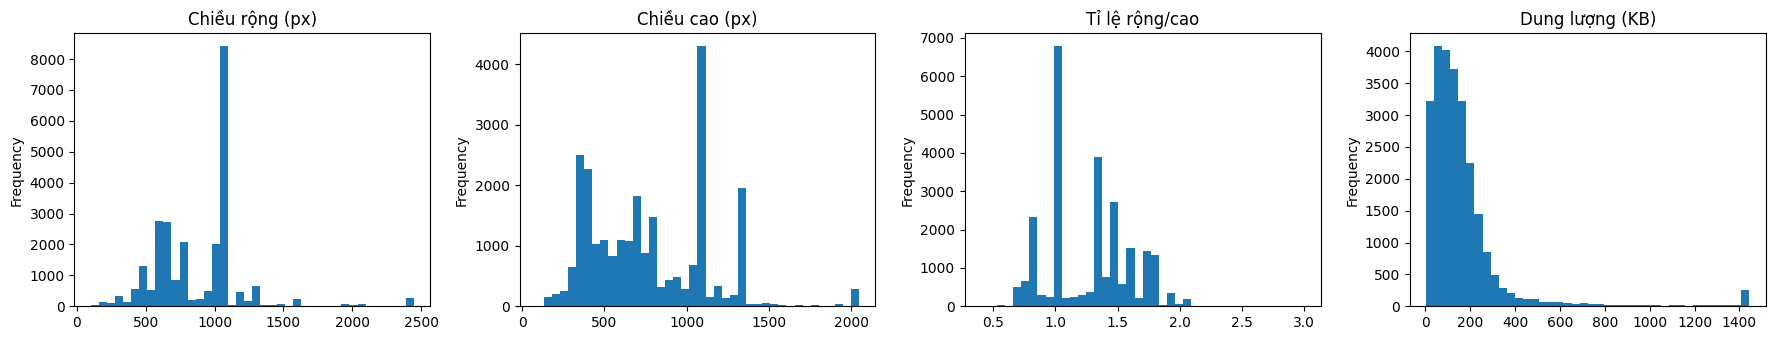

,so_anh,anh_hong,rong_TB,cao_TB,KB_trung_vi,trung_lap
dish,,,,,,
bun_bo_hue,1530,0,933.0,817.0,150.0,8
banh_mi,1336,0,958.0,779.0,120.0,1
banh_xeo,1173,0,927.0,791.0,148.0,1
bun_rieu,1151,0,962.0,877.0,159.0,7
banh_cuon,1140,0,913.0,789.0,131.0,5
chao_long,1073,0,931.0,859.0,124.0,1
hu_tieu,983,0,867.0,709.0,92.0,9
banh_canh,964,0,898.0,751.0,107.0,8
com_tam,942,0,896.0,758.0,120.0,2


In [5]:
import hashlib, io
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
from IPython.display import display

SCAN_WORKERS = 8

def scan_one(args):
    idx, fn = args
    try:
        with open(os.path.join(IMG_ROOT, fn), "rb") as f:
            b = f.read()
        md5 = hashlib.md5(b).hexdigest()
        im = Image.open(io.BytesIO(b))
        w, h = im.size
        im.verify()
        return idx, dict(ok=True, w=w, h=h, kb=len(b) / 1024, md5=md5)
    except Exception:
        return idx, dict(ok=False, w=0, h=0, kb=0.0, md5=None)

with ThreadPoolExecutor(SCAN_WORKERS) as ex:
    res = list(tqdm(ex.map(scan_one, zip(df.index, df.filename)), total=len(df), desc="Quét ảnh"))
stats = pd.DataFrame([r for _, r in res], index=[i for i, _ in res])
stats["min_side"] = stats[["w", "h"]].min(axis=1)
stats["aspect"] = stats.w / stats.h.replace(0, np.nan)

# ---- Báo cáo chất lượng ----
dup_mask = stats.md5.duplicated(keep=False) & stats.ok
tr_h = set(stats.loc[train_df.index, "md5"].dropna())
va_h = set(stats.loc[val_df.index, "md5"].dropna())
cnt = df.dish.value_counts()
report = {
    "Tổng số ảnh": len(df),
    "Số món": len(classes),
    "Ảnh hỏng/không đọc được": int((~stats.ok).sum()),
    "Ảnh có cạnh ngắn < 64px": int(((stats.min_side < 64) & stats.ok).sum()),
    "Ảnh thuộc nhóm trùng lặp": int(dup_mask.sum()),
    "Ảnh trùng giữa train và val (rò rỉ)": len(tr_h & va_h),
    "Món nhiều ảnh nhất": f"{cnt.idxmax()} ({cnt.max()})",
    "Món ít ảnh nhất": f"{cnt.idxmin()} ({cnt.min()})",
    "Tỉ lệ mất cân bằng (max/min)": round(cnt.max() / cnt.min(), 2),
}
display(pd.Series(report, name="Giá trị").to_frame())

# ---- Phân bố kích thước ----
ok = stats[stats.ok]
fig, ax = plt.subplots(1, 4, figsize=(18, 3.5))
ok.w.clip(upper=ok.w.quantile(0.99)).plot.hist(bins=40, ax=ax[0], title="Chiều rộng (px)")
ok.h.clip(upper=ok.h.quantile(0.99)).plot.hist(bins=40, ax=ax[1], title="Chiều cao (px)")
ok.aspect.clip(0.3, 3).plot.hist(bins=40, ax=ax[2], title="Tỉ lệ rộng/cao")
ok.kb.clip(upper=ok.kb.quantile(0.99)).plot.hist(bins=40, ax=ax[3], title="Dung lượng (KB)")
plt.tight_layout(); plt.show()

# ---- Tóm tắt theo món ----
tmp = df[["dish"]].join(stats)
summary = tmp.groupby("dish").agg(so_anh=("ok", "size"), anh_hong=("ok", lambda s: int((~s).sum())),
                                  rong_TB=("w", "mean"), cao_TB=("h", "mean"), KB_trung_vi=("kb", "median")).round(0)
summary["trung_lap"] = dup_mask.groupby(df.dish).sum().astype(int)
display(summary.sort_values("so_anh", ascending=False))

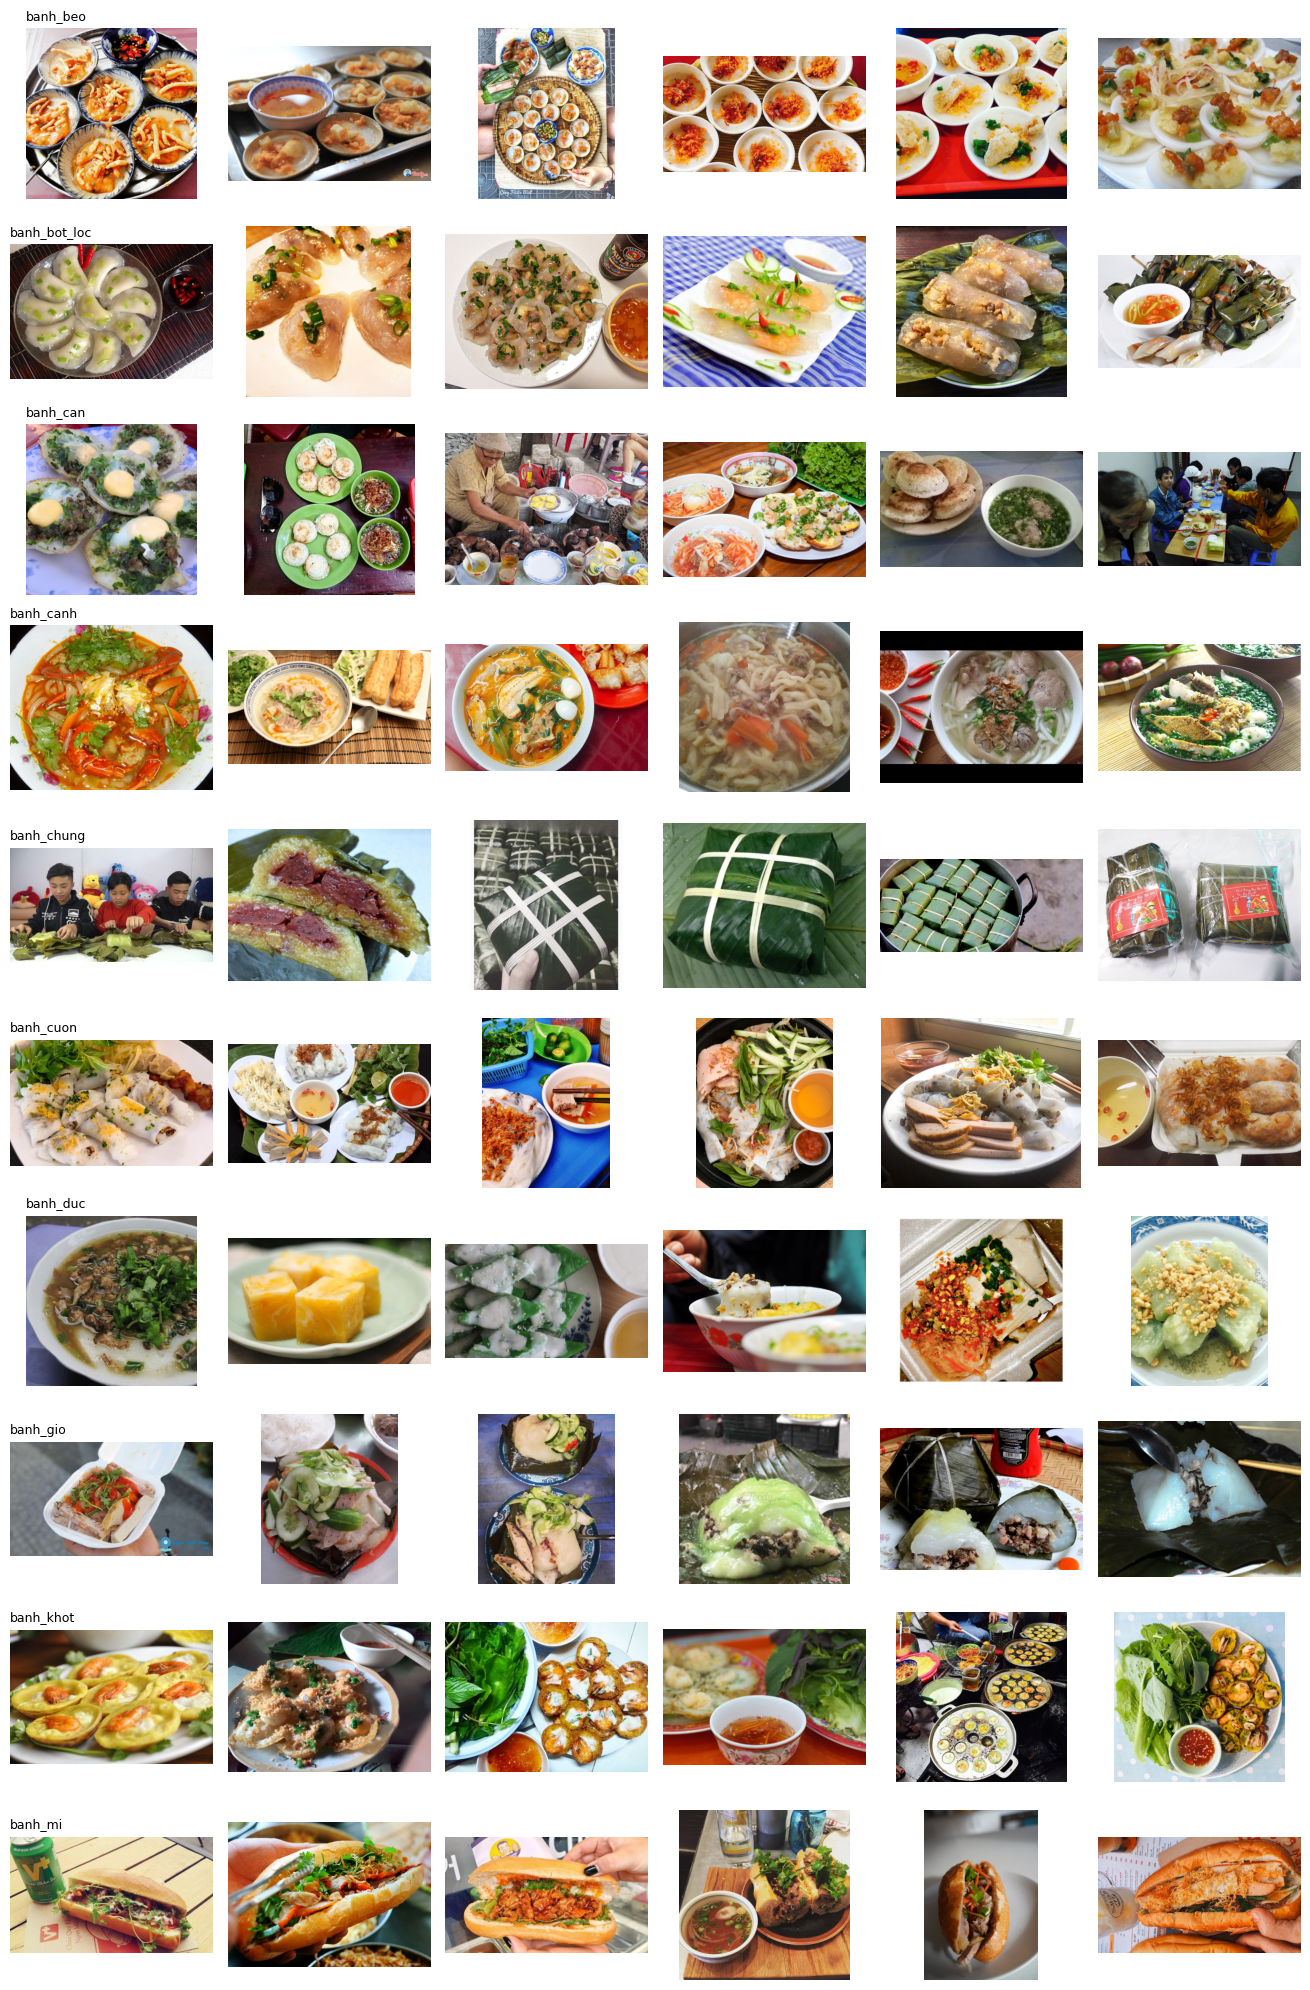

In [6]:
# Xem ảnh mẫu của từng món (đổi classes[:10] thành classes[10:20]... để xem món khác)
show_classes = classes[:10]
PER_CLASS = 6

fig, axes = plt.subplots(len(show_classes), PER_CLASS, figsize=(PER_CLASS * 2.2, len(show_classes) * 2.0))
axes = np.atleast_2d(axes)
for r, c in enumerate(show_classes):
    sub = df[df.dish == c]
    files_c = sub.sample(min(PER_CLASS, len(sub)), random_state=SEED).filename.tolist()
    for k in range(PER_CLASS):
        ax = axes[r, k]; ax.axis("off")
        if k < len(files_c):
            try:
                im = Image.open(os.path.join(IMG_ROOT, files_c[k])); im.draft("RGB", (256, 256))
                ax.imshow(im.convert("RGB"))
            except Exception:
                ax.text(0.5, 0.5, "lỗi", ha="center")
        if k == 0:
            ax.set_title(c, fontsize=9, loc="left")
plt.tight_layout(); plt.show()

## 6. Xử lý dữ liệu
Dựa trên kết quả quét ở bước trước, ô này:
1. Bỏ ảnh hỏng và ảnh quá nhỏ.
2. Bỏ ảnh trùng lặp trong train, và bỏ ảnh ở val đã xuất hiện trong train (tránh rò rỉ làm điểm đánh giá cao giả tạo).
3. Cho phép cân bằng các món bằng `WeightedRandomSampler` khi huấn luyện (`BALANCE = "sampler"`).
4. Lưu danh sách đã làm sạch ra `/content/labels_clean.csv`.

In [7]:
MIN_SIDE = 64               # bỏ ảnh có cạnh ngắn hơn giá trị này (px)
DROP_DUPLICATES = True      # bỏ ảnh trùng lặp
BALANCE = "sampler"         # "none" | "sampler"  (cân bằng các món khi huấn luyện)

n_tr0, n_va0 = len(train_df), len(val_df)

bad = (~stats.ok) | (stats.min_side < MIN_SIDE)
train_df = train_df[~bad.loc[train_df.index].values]
val_df   = val_df[~bad.loc[val_df.index].values]
print(f"Bỏ ảnh hỏng/quá nhỏ : train -{n_tr0 - len(train_df)}, val -{n_va0 - len(val_df)}")

if DROP_DUPLICATES:
    n_tr1, n_va1 = len(train_df), len(val_df)
    h_tr = stats.md5.loc[train_df.index]
    train_hashes = set(h_tr)
    train_df = train_df[~h_tr.duplicated().values]
    h_va = stats.md5.loc[val_df.index]
    val_df = val_df[(~h_va.duplicated().values) & (~h_va.isin(train_hashes).values)]
    print(f"Bỏ ảnh trùng lặp    : train -{n_tr1 - len(train_df)}, val -{n_va1 - len(val_df)}")

# Nếu có món biến mất hoàn toàn khỏi train thì cập nhật lại danh sách món
missing = set(classes) - set(train_df.dish)
if missing:
    print("Cảnh báo: các món không còn ảnh trong train, sẽ bị loại:", sorted(missing))
    classes = sorted(train_df.dish.unique())
    c2i = {c: i for i, c in enumerate(classes)}
    val_df = val_df[val_df.dish.isin(classes)]

df = pd.concat([train_df, val_df])
df[["filename", "dish", "score"]].to_csv("/content/labels_clean.csv", index=False)

cnt = train_df.dish.value_counts()
print(f"\nSau xử lý: train={len(train_df)}, val={len(val_df)}, số món={len(classes)}")
print(f"Tỉ lệ mất cân bằng trong train (max/min) = {cnt.max() / cnt.min():.2f}  | BALANCE = {BALANCE!r}")
print("Đã lưu danh sách sạch: /content/labels_clean.csv")

Bỏ ảnh hỏng/quá nhỏ : train -0, val -0
Bỏ ảnh trùng lặp    : train -21, val -12

Sau xử lý: train=17560, val=2503, số món=30
Tỉ lệ mất cân bằng trong train (max/min) = 3.45  | BALANCE = 'sampler'
Đã lưu danh sách sạch: /content/labels_clean.csv


## 7. Điểm sức khỏe (theo bảng dinh dưỡng)
Số liệu dưới đây chỉ là **minh họa** — thay bằng số liệu thật. Tên món phải trùng với tên món trong dữ liệu của bạn (món nào không có trong bảng sẽ cho `nan`).

In [8]:
# kcal / khẩu phần, protein (g), đường (g), natri (mg)  -- SỐ LIỆU MINH HỌA, hãy đối chiếu nguồn chính thống
NUTRITION = {
    "pho_bo":     dict(kcal=450, protein=25, sugar=4,  sodium=1500),
    "bun_cha":    dict(kcal=650, protein=30, sugar=15, sodium=1800),
    "banh_mi":    dict(kcal=420, protein=15, sugar=5,  sodium=900),
    "com_tam":    dict(kcal=750, protein=30, sugar=8,  sodium=1400),
    "goi_cuon":   dict(kcal=200, protein=10, sugar=3,  sodium=500),
    "bun_bo_hue": dict(kcal=550, protein=28, sugar=5,  sodium=1700),
}
# Tên món trong dữ liệu -> khóa trong bảng trên (thêm nếu tên thư mục của bạn khác)
ALIAS = {"pho": "pho_bo"}

def health_score(dish: str) -> float:
    """Điểm sức khỏe 0-10 theo quy tắc đơn giản (calo, đạm, đường, natri)."""
    n = NUTRITION.get(ALIAS.get(dish, dish))
    if not n:
        return float("nan")
    s = 10.0
    s -= max(0, n["kcal"] - 500) / 100
    s -= max(0, n["sodium"] - 1000) / 400
    s -= max(0, n["sugar"] - 10) / 5
    s += min(n["protein"], 30) / 15
    return round(max(0.0, min(10.0, s)), 1)

has_info = [c for c in classes if ALIAS.get(c, c) in NUTRITION]
print(f"{len(has_info)}/{len(classes)} món có bảng dinh dưỡng:", has_info)
print("Món chưa có dữ liệu dinh dưỡng:", [c for c in classes if c not in has_info])

5/30 món có bảng dinh dưỡng: ['banh_mi', 'bun_bo_hue', 'com_tam', 'goi_cuon', 'pho']
Món chưa có dữ liệu dinh dưỡng: ['banh_beo', 'banh_bot_loc', 'banh_can', 'banh_canh', 'banh_chung', 'banh_cuon', 'banh_duc', 'banh_gio', 'banh_khot', 'banh_pia', 'banh_tet', 'banh_trang_nuong', 'banh_xeo', 'bun_dau_mam_tom', 'bun_mam', 'bun_rieu', 'bun_thit_nuong', 'ca_kho_to', 'canh_chua', 'cao_lau', 'chao_long', 'hu_tieu', 'mi_quang', 'nem_chua', 'xoi_xeo']


## 8. Dataset & augmentation

In [9]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

TRAIN_TF = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
EVAL_TF = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class FoodDataset(Dataset):
    def __init__(self, df, root, class_to_idx, tf):
        self.df, self.root, self.c2i, self.tf = df.reset_index(drop=True), root, class_to_idx, tf
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        for _ in range(5):                       # bỏ qua ảnh hỏng, thử mẫu khác
            r = self.df.iloc[i]
            try:
                img = Image.open(os.path.join(self.root, r.filename))
                img.draft("RGB", (512, 512))     # giải mã JPEG nhỏ hơn -> nạp ảnh lớn nhanh hơn
                img = img.convert("RGB")
                break
            except Exception:
                i = random.randrange(len(self.df))
        else:
            raise RuntimeError("Nhiều ảnh liên tiếp bị hỏng, hãy kiểm tra dữ liệu.")
        return self.tf(img), self.c2i[r.dish], torch.tensor(float(r.score) / 10.0, dtype=torch.float32)


train_ds = FoodDataset(train_df, IMG_ROOT, c2i, TRAIN_TF)
if BALANCE == "sampler":
    from torch.utils.data import WeightedRandomSampler
    _cnt = train_df.dish.value_counts()
    _w = train_df.dish.map(lambda d: 1.0 / _cnt[d]).values
    sampler = WeightedRandomSampler(torch.tensor(_w, dtype=torch.double), num_samples=len(train_df), replacement=True)
    dl_train = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=2, pin_memory=True)
else:
    dl_train = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
dl_val = DataLoader(FoodDataset(val_df, IMG_ROOT, c2i, EVAL_TF), batch_size=BATCH_SIZE,
                    shuffle=False, num_workers=2, pin_memory=True)
print("train:", len(train_df), "| val:", len(val_df), "| cân bằng:", BALANCE)

def denorm(t):
    """Tensor đã chuẩn hóa -> mảng ảnh để hiển thị."""
    m = torch.tensor(MEAN).view(3, 1, 1); sd = torch.tensor(STD).view(3, 1, 1)
    return (t.cpu() * sd + m).clamp(0, 1).permute(1, 2, 0).numpy()

train: 17560 | val: 2503 | cân bằng: sampler


### Xem thử augmentation
Ảnh gốc (cột đầu) và 5 phiên bản ngẫu nhiên mà mô hình sẽ thấy khi huấn luyện. Nếu ảnh bị cắt mất món chính quá nhiều, hãy tăng `scale` trong `RandomResizedCrop`.

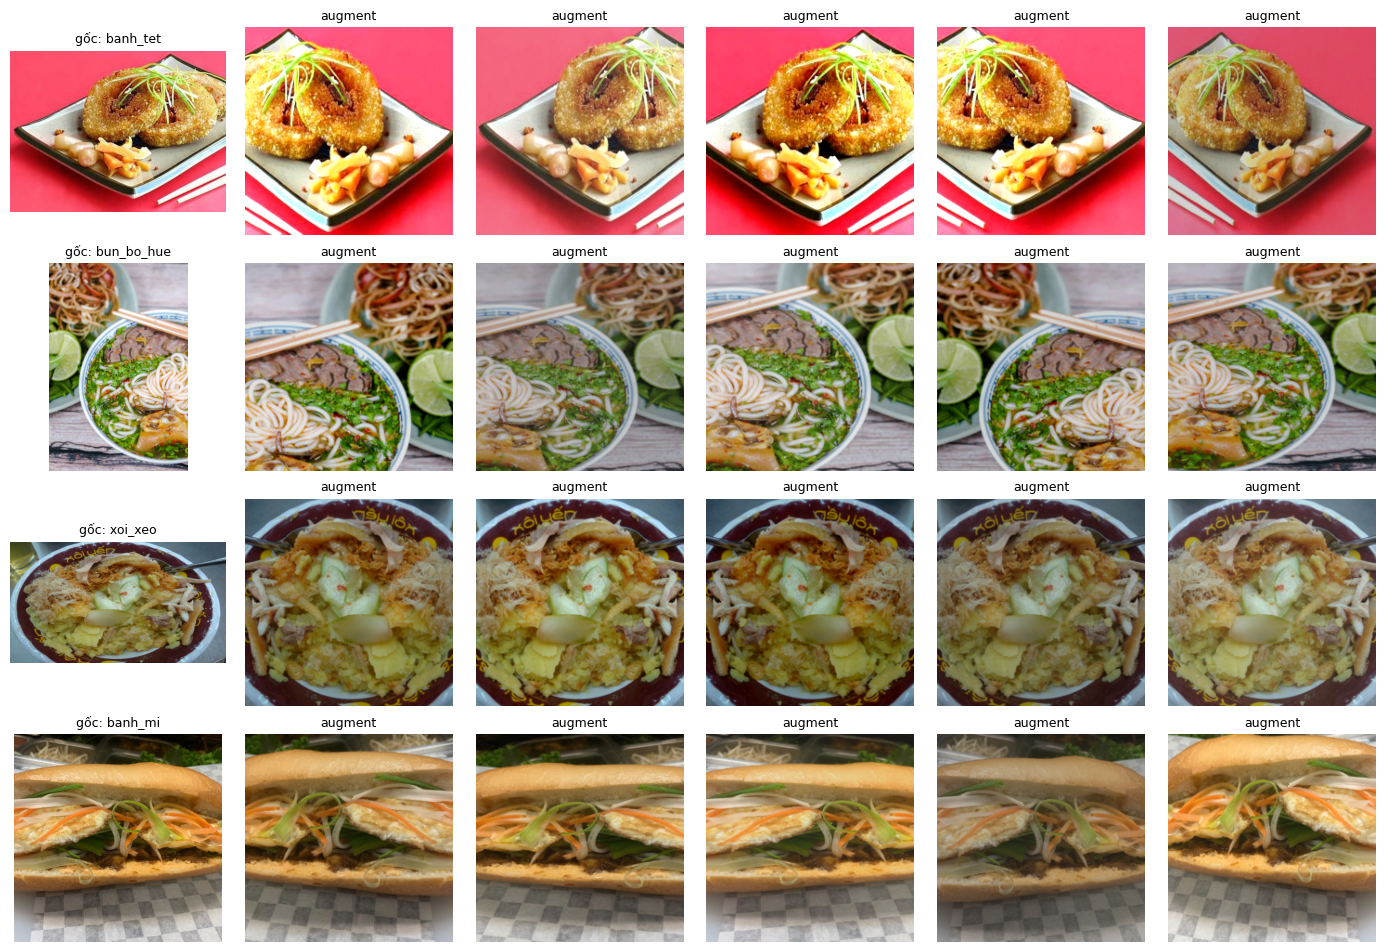

In [10]:
samples = train_df.sample(min(4, len(train_df)), random_state=1)
fig, axes = plt.subplots(len(samples), 6, figsize=(14, 2.4 * len(samples)))
axes = np.atleast_2d(axes)
for r, (_, row) in enumerate(samples.iterrows()):
    img = Image.open(os.path.join(IMG_ROOT, row.filename)); img.draft("RGB", (512, 512)); img = img.convert("RGB")
    axes[r, 0].imshow(img); axes[r, 0].set_title(f"gốc: {row.dish}", fontsize=9)
    for k in range(1, 6):
        axes[r, k].imshow(denorm(TRAIN_TF(img))); axes[r, k].set_title("augment", fontsize=9)
    for a in axes[r]:
        a.axis("off")
plt.tight_layout(); plt.show()

## 9. Kiến trúc mô hình (backbone dùng chung + 2 đầu ra)

In [11]:
class VNFoodNet(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        bb = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
        feat = bb.classifier[1].in_features
        bb.classifier = nn.Identity()
        self.backbone = bb
        self.cls_head = nn.Sequential(nn.Dropout(0.3), nn.Linear(feat, n_classes))
        self.score_head = nn.Sequential(nn.Linear(feat, 128), nn.ReLU(), nn.Linear(128, 1), nn.Sigmoid())

    def forward(self, x):
        f = self.backbone(x)
        return self.cls_head(f), self.score_head(f).squeeze(1)

model = VNFoodNet(len(classes)).to(DEVICE)
print("Số tham số:", round(sum(p.numel() for p in model.parameters()) / 1e6, 2), "triệu")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 227MB/s]


Số tham số: 4.21 triệu


## 10. Huấn luyện

In [12]:
def evaluate(model, loader):
    model.eval()
    correct = n = 0
    mae = 0.0
    all_pred, all_true = [], []
    with torch.no_grad():
        for x, y, s in loader:
            x, y, s = x.to(DEVICE), y.to(DEVICE), s.to(DEVICE)
            logits, pred = model(x)
            p = logits.argmax(1)
            correct += (p == y).sum().item()
            mae += (pred - s).abs().sum().item() * 10
            n += len(y)
            all_pred += p.cpu().tolist(); all_true += y.cpu().tolist()
    return correct / n, mae / n, all_true, all_pred

def train(model, epochs=EPOCHS):
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    ce, huber = nn.CrossEntropyLoss(label_smoothing=0.1), nn.SmoothL1Loss()
    history = {"loss": [], "acc": [], "mae": []}
    best = -1.0

    for ep in range(epochs):
        model.train()
        total = 0.0
        for x, y, s in dl_train:
            x, y, s = x.to(DEVICE), y.to(DEVICE), s.to(DEVICE)
            logits, pred = model(x)
            loss = ce(logits, y) + SCORE_LOSS_WEIGHT * huber(pred, s)
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(y)
        sched.step()

        acc, mae, _, _ = evaluate(model, dl_val)
        history["loss"].append(total / len(train_df)); history["acc"].append(acc); history["mae"].append(mae)
        msg = f"Epoch {ep+1:02d}/{epochs} | loss={history['loss'][-1]:.3f} | acc={acc:.3f}"
        if HAS_SCORE:
            msg += f" | MAE điểm={mae:.2f}/10"
        print(msg)

        if acc > best:
            best = acc
            torch.save({"model": model.state_dict(), "classes": classes, "has_score": HAS_SCORE}, CKPT)
    print(f"\nĐã lưu mô hình tốt nhất (acc={best:.3f}) vào {CKPT}")
    return history

history = train(model)

Epoch 01/15 | loss=1.545 | acc=0.803
Epoch 02/15 | loss=1.065 | acc=0.832
Epoch 03/15 | loss=0.962 | acc=0.851
Epoch 04/15 | loss=0.898 | acc=0.863
Epoch 05/15 | loss=0.850 | acc=0.862
Epoch 06/15 | loss=0.817 | acc=0.869
Epoch 07/15 | loss=0.789 | acc=0.875
Epoch 08/15 | loss=0.769 | acc=0.877
Epoch 09/15 | loss=0.753 | acc=0.879
Epoch 10/15 | loss=0.737 | acc=0.888
Epoch 11/15 | loss=0.725 | acc=0.888
Epoch 12/15 | loss=0.717 | acc=0.887
Epoch 13/15 | loss=0.708 | acc=0.889
Epoch 14/15 | loss=0.705 | acc=0.890
Epoch 15/15 | loss=0.707 | acc=0.888

Đã lưu mô hình tốt nhất (acc=0.890) vào /content/vn_food_model.pt


## 11. Đánh giá kết quả
Phần cơ bản: đồ thị huấn luyện, báo cáo phân loại, confusion matrix. Các ô bên dưới đánh giá chi tiết hơn.

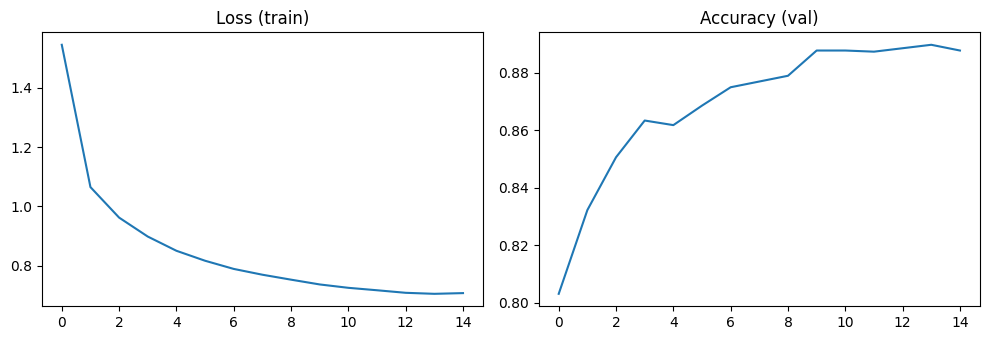

Accuracy=0.890

                  precision    recall  f1-score   support

        banh_beo       0.88      0.89      0.89        65
    banh_bot_loc       0.86      0.81      0.83        73
        banh_can       0.92      0.92      0.92        72
       banh_canh       0.78      0.72      0.75        97
      banh_chung       0.79      0.92      0.85        50
       banh_cuon       0.91      0.91      0.91       114
        banh_duc       0.75      0.71      0.73        65
        banh_gio       0.88      0.88      0.88        64
       banh_khot       0.89      0.93      0.91        83
         banh_mi       0.98      0.98      0.98       133
        banh_pia       0.96      0.98      0.97        45
        banh_tet       0.94      0.87      0.90        68
banh_trang_nuong       0.91      0.91      0.91        80
        banh_xeo       0.92      0.93      0.92       116
      bun_bo_hue       0.79      0.86      0.82       153
 bun_dau_mam_tom       0.98      0.99      0.98        

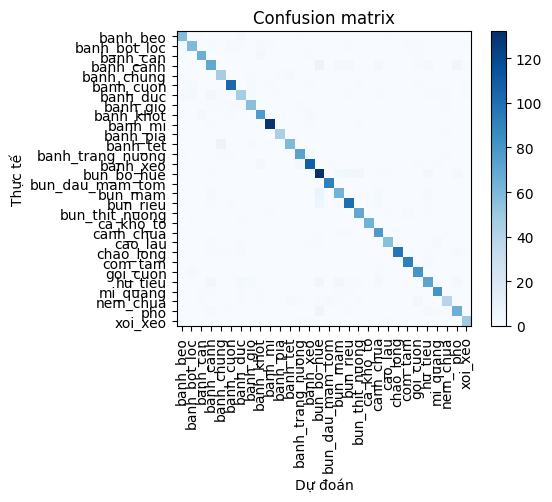

In [14]:
n_plots = 3 if HAS_SCORE else 2
fig, ax = plt.subplots(1, n_plots, figsize=(5 * n_plots, 3.5))
ax[0].plot(history["loss"]); ax[0].set_title("Loss (train)")
ax[1].plot(history["acc"]);  ax[1].set_title("Accuracy (val)")
if HAS_SCORE:
    ax[2].plot(history["mae"]); ax[2].set_title("MAE điểm (val, thang 10)")
plt.tight_layout(); plt.show()

# nạp lại mô hình tốt nhất
ck = torch.load(CKPT, map_location=DEVICE, weights_only=False)
model.load_state_dict(ck["model"])
acc, mae, y_true, y_pred = evaluate(model, dl_val)
print(f"Accuracy={acc:.3f}" + (f" | MAE điểm={mae:.2f}/10" if HAS_SCORE else "") + "\n")
labels_idx = list(range(len(classes)))
print(classification_report(y_true, y_pred, labels=labels_idx, target_names=classes, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=labels_idx)
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(labels_idx, classes, rotation=90); plt.yticks(labels_idx, classes)
plt.xlabel("Dự đoán"); plt.ylabel("Thực tế"); plt.title("Confusion matrix")
plt.tight_layout(); plt.show()

### Đánh giá chi tiết
Các ô dưới đây dùng mô hình tốt nhất đã nạp lại ở ô trên, chạy trên tập val.

In [ ]:
@torch.no_grad()
def collect(model, loader):
    """Chạy mô hình trên toàn bộ tập, trả về xác suất, điểm dự đoán, nhãn thật, điểm thật (thang 10)."""
    model.eval()
    P, S, Y, T = [], [], [], []
    for x, y, s in loader:
        logits, sc = model(x.to(DEVICE))
        P.append(logits.softmax(1).cpu()); S.append(sc.cpu() * 10); Y.append(y); T.append(s * 10)
    return torch.cat(P).numpy(), torch.cat(S).numpy(), torch.cat(Y).numpy(), torch.cat(T).numpy()

probs, score_pred, y_true, score_true = collect(model, dl_val)
y_pred = probs.argmax(1)
K = len(classes)
print("Đã dự đoán", len(y_true), "ảnh val")

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, top_k_accuracy_score

res = {"Top-1 accuracy": accuracy_score(y_true, y_pred)}
for k in (3, 5):
    if K > k:
        res[f"Top-{k} accuracy"] = top_k_accuracy_score(y_true, probs, k=k, labels=np.arange(K))
res["Macro F1 (trung bình các món)"] = f1_score(y_true, y_pred, average="macro", zero_division=0)
res["Weighted F1"] = f1_score(y_true, y_pred, average="weighted", zero_division=0)
display(pd.Series(res, name="Giá trị").round(4).to_frame())

p, r, f1, sup = precision_recall_fscore_support(y_true, y_pred, labels=np.arange(K), zero_division=0)
per_class = pd.DataFrame({"precision": p, "recall": r, "f1": f1, "so_anh_val": sup}, index=classes).round(3)
per_class = per_class.sort_values("f1")
display(per_class)

fig, ax = plt.subplots(figsize=(7, max(3, K * 0.3)))
ax.barh(per_class.index, per_class.f1, color="#4C78A8")
ax.set_xlim(0, 1); ax.set_xlabel("F1"); ax.set_title("F1 theo từng món (thấp -> cao)")
plt.tight_layout(); plt.show()
print("Món khó nhất:", per_class.index[:3].tolist(), "| Món dễ nhất:", per_class.index[-3:].tolist())

In [ ]:
cm = confusion_matrix(y_true, y_pred, labels=np.arange(K))
cmn = cm / np.clip(cm.sum(1, keepdims=True), 1, None)

size = max(6, K * 0.45)
plt.figure(figsize=(size, size))
plt.imshow(cmn, cmap="Blues", vmin=0, vmax=1); plt.colorbar(fraction=0.046)
plt.xticks(range(K), classes, rotation=90, fontsize=8); plt.yticks(range(K), classes, fontsize=8)
if K <= 15:
    for i in range(K):
        for j in range(K):
            plt.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=7,
                     color="white" if cmn[i, j] > 0.5 else "black")
plt.xlabel("Dự đoán"); plt.ylabel("Thực tế"); plt.title("Confusion matrix (chuẩn hóa theo hàng = recall)")
plt.tight_layout(); plt.show()

pairs = [(classes[i], classes[j], int(cm[i, j]), round(cmn[i, j], 3))
         for i in range(K) for j in range(K) if i != j and cm[i, j] > 0]
pairs = sorted(pairs, key=lambda t: -t[2])[:10]
print("Các cặp món bị nhầm nhiều nhất:")
display(pd.DataFrame(pairs, columns=["thực tế", "bị đoán thành", "số ảnh", "tỉ lệ"]))

In [ ]:
# Ảnh bị đoán sai nhưng mô hình rất tự tin (thường là nhãn sai hoặc ảnh gây hiểu nhầm)
conf = probs.max(1)
wrong = np.where(y_pred != y_true)[0]
if len(wrong) == 0:
    print("Không có ảnh nào bị đoán sai trên tập val.")
else:
    order = wrong[np.argsort(-conf[wrong])][:12]
    cols = 4
    rows = int(np.ceil(len(order) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.2, rows * 3.4))
    axes = np.atleast_1d(axes).ravel()
    for a in axes:
        a.axis("off")
    for a, idx in zip(axes, order):
        row = val_df.iloc[idx]
        im = Image.open(os.path.join(IMG_ROOT, row.filename)); im.draft("RGB", (384, 384))
        a.imshow(im.convert("RGB"))
        a.set_title(f"Thật: {classes[y_true[idx]]}\nĐoán: {classes[y_pred[idx]]} ({conf[idx]:.0%})", fontsize=9, color="#b00020")
    plt.tight_layout(); plt.show()
    print(f"Tổng số ảnh sai: {len(wrong)}/{len(y_true)}")

In [ ]:
# Độ hiệu chỉnh: khi mô hình nói "tự tin 80%" thì có thực sự đúng ~80% không?
conf = probs.max(1)
correct = (y_pred == y_true).astype(float)
bins = np.linspace(0, 1, 11)
ids = np.clip(np.digitize(conf, bins) - 1, 0, 9)
bin_acc, bin_conf, bin_n = [], [], []
for b in range(10):
    m = ids == b
    bin_n.append(m.sum())
    bin_acc.append(correct[m].mean() if m.any() else np.nan)
    bin_conf.append(conf[m].mean() if m.any() else np.nan)
ece = sum(n / len(conf) * abs(a - c) for n, a, c in zip(bin_n, bin_acc, bin_conf) if n > 0)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(conf[correct == 1], bins=20, alpha=0.7, label="đoán đúng")
ax[0].hist(conf[correct == 0], bins=20, alpha=0.7, label="đoán sai")
ax[0].set_title("Phân bố độ tự tin"); ax[0].set_xlabel("độ tự tin"); ax[0].legend()
ax[1].plot([0, 1], [0, 1], "--", color="gray", label="hiệu chỉnh hoàn hảo")
ax[1].plot(bin_conf, bin_acc, "o-", label="mô hình")
ax[1].set_xlabel("độ tự tin trung bình"); ax[1].set_ylabel("độ chính xác thực tế")
ax[1].set_title(f"Reliability diagram (ECE = {ece:.3f})"); ax[1].legend()
plt.tight_layout(); plt.show()
print("ECE càng gần 0 càng tốt. Nếu mô hình thường 'tự tin quá mức', cân nhắc temperature scaling hoặc đặt ngưỡng từ chối (vd: độ tự tin < 0.5 -> 'không chắc').")

In [ ]:
if not HAS_SCORE:
    print("Dữ liệu không có điểm chấm thật -> bỏ qua đánh giá nhánh chấm điểm.")
else:
    err = score_pred - score_true
    mae = np.abs(err).mean()
    rmse = np.sqrt((err ** 2).mean())
    pear = np.corrcoef(score_pred, score_true)[0, 1]
    spear = pd.Series(score_pred).corr(pd.Series(score_true), method="spearman")
    base = np.abs(score_true - train_df.score.mean()).mean()   # đoán luôn điểm trung bình của train
    display(pd.Series({"MAE": mae, "RMSE": rmse, "Pearson": pear, "Spearman": spear,
                       "MAE baseline (luôn đoán trung bình)": base}, name="Giá trị").round(3).to_frame())
    print("Mô hình tốt hơn baseline" if mae < base else "Mô hình CHƯA tốt hơn baseline -> cần thêm/chấm lại dữ liệu điểm")

    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    ax[0].scatter(score_true, score_pred, s=8, alpha=0.5)
    ax[0].plot([0, 10], [0, 10], "--", color="gray")
    ax[0].set_xlabel("điểm thật"); ax[0].set_ylabel("điểm dự đoán"); ax[0].set_title("Dự đoán vs thực tế")
    ax[1].hist(err, bins=30); ax[1].set_title("Phân bố sai số (dự đoán - thật)")
    per_cls = pd.Series(np.abs(err)).groupby(np.array(classes)[y_true]).mean().sort_values()
    ax[2].barh(per_cls.index, per_cls.values); ax[2].set_title("MAE theo món")
    plt.tight_layout(); plt.show()

### Grad-CAM: mô hình đang nhìn vào đâu?
Vùng nóng (đỏ) là vùng ảnh ảnh hưởng nhiều nhất đến quyết định phân loại. Nếu mô hình nhìn vào bàn, đĩa hoặc nền thay vì món ăn, nó đang học sai đặc trưng.

In [ ]:
def gradcam(model, tensor, class_idx=None):
    """Grad-CAM trên lớp convolution cuối của EfficientNet."""
    model.eval()
    store = {}
    def hook(m, i, o):
        o.retain_grad(); store["a"] = o
    h = model.backbone.features.register_forward_hook(hook)
    with torch.enable_grad():
        logits, _ = model(tensor)
        c = logits.argmax(1).item() if class_idx is None else class_idx
        model.zero_grad()
        logits[0, c].backward()
    h.remove()
    a, g = store["a"], store["a"].grad
    cam = torch.relu((g.mean(dim=(2, 3), keepdim=True) * a).sum(1))[0].detach().cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam, c, logits.softmax(1)[0, c].item()

n_show = min(6, len(val_df))
pick = np.random.RandomState(SEED).choice(len(val_df), n_show, replace=False)
fig, axes = plt.subplots(2, n_show, figsize=(n_show * 2.8, 6))
axes = axes.reshape(2, n_show)
for col, idx in enumerate(pick):
    row = val_df.iloc[idx]
    im = Image.open(os.path.join(IMG_ROOT, row.filename)); im.draft("RGB", (512, 512)); im = im.convert("RGB")
    x = EVAL_TF(im).unsqueeze(0).to(DEVICE)
    cam, c, p = gradcam(model, x)
    base_img = denorm(x[0])
    cam_img = np.array(Image.fromarray((cam * 255).astype("uint8")).resize((224, 224), Image.BILINEAR)) / 255.0
    overlay = 0.55 * base_img + 0.45 * plt.cm.jet(cam_img)[..., :3]
    axes[0, col].imshow(base_img); axes[0, col].axis("off")
    axes[0, col].set_title(f"thật: {row.dish}", fontsize=9)
    axes[1, col].imshow(overlay); axes[1, col].axis("off")
    axes[1, col].set_title(f"đoán: {classes[c]} ({p:.0%})", fontsize=9, color="green" if classes[c] == row.dish else "#b00020")
plt.tight_layout(); plt.show()

## 12. Dự đoán trên ảnh mới

In [ ]:
def predict(image_path, show=True):
    ck = torch.load(CKPT, map_location=DEVICE)
    cls = ck["classes"]
    has_score = ck.get("has_score", True)
    net = VNFoodNet(len(cls)).to(DEVICE)
    net.load_state_dict(ck["model"]); net.eval()

    img = Image.open(image_path).convert("RGB")
    x = EVAL_TF(img).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        logits, score = net(x)
        probs = logits.softmax(1)[0]
    top = probs.topk(min(3, len(cls)))
    dish = cls[top.indices[0]]
    result = {
        "mon_an": dish,
        "do_tin_cay": round(top.values[0].item(), 3),
        "top3": {cls[i]: round(p.item(), 3) for p, i in zip(top.values, top.indices)},
        "diem_trinh_bay": round(score.item() * 10, 1) if has_score else None,
        "diem_suc_khoe": health_score(dish),
    }
    if show:
        plt.imshow(img); plt.axis("off")
        title = f"{dish} ({result['do_tin_cay']*100:.0f}%)"
        if has_score:
            title += f" | trình bày {result['diem_trinh_bay']}/10"
        plt.title(title); plt.show()
    print(json.dumps(result, ensure_ascii=False, indent=2))
    return result

# Thử với một ảnh trong tập validation
predict(os.path.join(IMG_ROOT, val_df.iloc[0].filename));

### Thử với ảnh của bạn (upload từ máy)

In [ ]:
from google.colab import files
up = files.upload()
for name in up:
    predict(name)

### Tải mô hình đã huấn luyện về máy / lưu vào Drive

In [15]:
!pip install -q gradio

import gradio as gr
import torch

# Nạp mô hình tốt nhất đã lưu
ck = torch.load(CKPT, map_location=DEVICE, weights_only=False)
model.load_state_dict(ck["model"])
model.eval()
demo_classes = ck["classes"]
demo_has_score = ck.get("has_score", True)


def predict_demo(img):
    if img is None:
        return None, "Hãy tải lên một ảnh món ăn."
    img = img.convert("RGB")
    x = EVAL_TF(img).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        logits, score = model(x)
    probs = logits.softmax(1)[0].cpu()
    top = probs.topk(min(5, len(demo_classes)))

    label_dict = {demo_classes[i]: float(p) for p, i in zip(top.values, top.indices)}
    dish = demo_classes[top.indices[0]]

    lines = [f"### 🍜 {dish}  ({top.values[0].item():.0%})"]
    if demo_has_score:
        lines.append(f"**Điểm trình bày:** {score.item() * 10:.1f}/10")
    hs = health_score(dish)
    if hs == hs:  # khác NaN
        lines.append(f"**Điểm sức khỏe:** {hs}/10")
    else:
        lines.append("**Điểm sức khỏe:** chưa có dữ liệu dinh dưỡng cho món này")
    if top.values[0].item() < 0.5:
        lines.append("⚠️ Mô hình không chắc chắn, hãy thử ảnh rõ hơn hoặc chụp gần món ăn hơn.")
    return label_dict, "\n\n".join(lines)


demo = gr.Interface(
    fn=predict_demo,
    inputs=gr.Image(type="pil", label="Ảnh món ăn"),
    outputs=[
        gr.Label(num_top_classes=5, label="Dự đoán món"),
        gr.Markdown(label="Kết quả"),
    ],
    title="AI phân loại & chấm điểm món ăn Việt Nam",
    description="Tải lên ảnh một món ăn Việt để nhận diện món, điểm trình bày và điểm sức khỏe.",
)

demo.launch(share=True)   # share=True tạo link công khai tạm thời để mở trên điện thoại

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ce35836b19a8e33b5b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# Tải về máy
from google.colab import files
files.download(CKPT)

# Hoặc lưu vào Google Drive (cần đã mount Drive ở bước 3):
# shutil.copy(CKPT, "/content/drive/MyDrive/vn_food_model.pt")

## Hướng nâng cấp
- Đổi backbone sang **ConvNeXt / ViT / CLIP** để phân biệt tốt hơn các món giống nhau (bún bò Huế vs bún riêu).
- Chấm điểm bằng **nhiều người** cho mỗi ảnh rồi lấy trung bình để giảm nhiễu nhãn.
- Ước lượng **khẩu phần** từ ảnh để tính calo sát thực tế.
- Fine-tune 2 giai đoạn: đóng băng backbone vài epoch đầu, sau đó mở khóa toàn bộ với LR nhỏ hơn.
- Đóng gói thành **API (FastAPI)** hoặc ứng dụng di động.